In [ ]:
# LangGraph Core components 

In [ ]:
#  State - A shared data structure that holds the current information or context                
#            of an entire application (like an application's memory, keeping track of variables)

#  Nodes - Individual functions or operations that perform specific tasks within the graph   
#    
#  Graph - A structure which maps out how different tasks(nodes) are connected and executed     
#          Graph visually represents the workflow                                
#                
#  Edges - connections between nodes that determine the flow of execution        
#                
#  Conditional edges - specialized connections that decide the next node to execute based on    
#                      specific conditions or logic applied to the current state        
#         
#  StateGraph - a class used in langGraph to build and compile graph structure                   

d:\Trainings\Clients\Ascendion_Agentic_AI\Live_class\.venv\Lib\site-packages\langchain_core\utils\pydantic.py:42: UserWarning: Core Pydantic V1 functionality isn't compatible with Python 3.14 or greater.
  from pydantic.v1 import BaseModel as BaseModelV1


Hey Arib, How is your day going


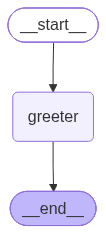

In [ ]:
# sample workflow demo 1 : single input graph                                                                                                     
from typing import TypedDict                                           
from langgraph.graph import StateGraph                                 
                                                                       
                                                                       
# create the agent state                                               
class AgentState(TypedDict):                                           
    message : str                                                                                                                                                                                     
                                                                       
def greeting_node(state:AgentState):                                   
    """ Simple node that adds a greeting message to the agent state""" 
    state['message'] = "Hey " + state["message"] + ", How is your day going?"
    return state                                                       
                                                                       
                                                                       
# create the graph flow                                                
graph = StateGraph(AgentState)                                         
                                                                       
                                                                       
graph.add_node("greeter",greeting_node)                                
graph.set_entry_point("greeter")                                       
graph.set_finish_point("greeter")                                      
                                                                       
                                                                       
app = graph.compile()                                                  
result = app.invoke({"message":"Arib"})                                
print(result["message"])                                               
                                                                       
                                                                       
# GRAPH FLOW                                                           
# START                   ___start____                                 
#  ↓                           ↓                                       
# Node                     greeter                                     
#  ↓                           ↓                                       
# End                      ___end___                                   
                                                                       
                                                                       
from IPython.display import Image,display                              
display(Image(app.get_graph().draw_mermaid_png()))                                                                        
# with open("graph.png", "wb") as f:                                     
#     f.write(app.get_graph().draw_mermaid_png())  #display the images   

In [ ]:
# Demo 2 agent langGraph fundamentals
# Multiple inputs graph                                  
# 1. Define a more complex AgentState                              
# 2. Create a processing node that performs operations on list data
# 3. Set up a LangGraph that processes and outputs computed results
# 4. Invoke the graph with structured inputs and retrieve outputs. 
# Main Goal: Learn how to handle multiple inputs                   

from typing import TypedDict,List
from langgraph.graph import StateGraph

class AgentState(TypedDict):
    values:List[int]
    name:str
    result:str

def process_values(state:AgentState) -> AgentState:
    """ This function handles different inputs"""
    state["result"] = f"Hi there {state['name']}! Your sum = {sum(state['values'])}"
    return state 

graph = StateGraph(AgentState)
graph.add_node("processor",process_values)
graph.set_entry_point("processor")
graph.set_finish_point("processor")
app = graph.compile()
app.invoke({"values":[10,20,30,40],"name":"Demo1"})

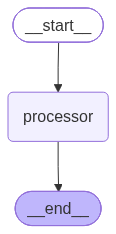

In [6]:
app

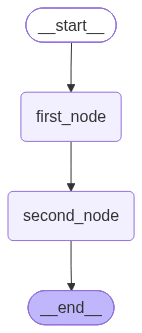

In [ ]:
# Demo 3 : 
# 1. Create multiple Nodes that sequentially process and update different parts of the state.
# 2. Connect Nodes together in a graph
# 3. Invoke the Graph and see how the state is transformed step-by-step.
# Main Goal: Create and handle multiple Nodes

from typing import TypedDict,List     
from langgraph.graph import StateGraph

class AgentState(TypedDict):
    name : str
    age : str 
    final : str 

def first_node(state:AgentState) -> AgentState:
    """ This is the first node of our sequence"""
    state['final'] = f"Hi! {state['name']}!"
    return state 

def second_node(state:AgentState) -> AgentState:
    """ This is the second node of our sequence"""
    state['final'] = state['final'] + f"You are {state['age']} years old!"
    return state 

graph = StateGraph(AgentState)
graph.add_node("first_node",first_node)
graph.add_node("second_node",second_node)
graph.add_edge("first_node","second_node")
graph.set_entry_point("first_node")
graph.set_finish_point("second_node")
app = graph.compile()
app

In [15]:
result = app.invoke({"name":"demo2","age":25})
result

{'name': 'demo2', 'age': 25, 'final': 'Hi! demo2!You are 25 years old!'}

In [ ]:
# Exercise for Demo 3 

# Your task:

# Accept a user's name, age, and a list of their skills.
# Pass the state through three nodes that:
# First node: Personalizes the name field with a greeting.
# Second node: Describes the user's age.
# Third node: Lists the user's skills in a formatted string.
# The final output in the result field should be a combined message in this format:

# Output: "Linda, welcome to the system! You are 31 years old! 
#                              You have skills in: Python Machine Learning, and LangGraph"

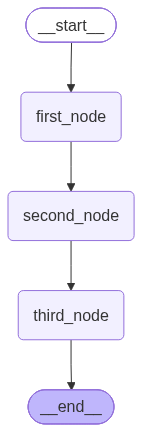

In [17]:
from typing import TypedDict,List 
from langgraph.graph import StateGraph

class AgentState(TypedDict):
    name : str
    age : str 
    skills : List[str]
    final : str

def first_node(state:AgentState)->AgentState:
    """This is the first node of our sequence"""
    state['final'] = f"Hi {state['name']}! "
    return state                            

def second_node(state:AgentState)->AgentState:   
    """This is the second node of our sequence"""
    state['final'] = state['final'] + f"You are {state['age']} years old!"
    return state                              

def third_node(state:AgentState)->AgentState:             
    """This is the third node of our sequence"""        
    state['final'] = state['final'] + f"You have skills in {','.join(state['skills'])}"
    return state                                    


graph = StateGraph(AgentState)            
graph.add_node("first_node",first_node)   
graph.add_node("second_node",second_node) 
graph.add_node("third_node",third_node) 
graph.add_edge("first_node","second_node")
graph.add_edge("second_node","third_node")
graph.set_entry_point("first_node")       
graph.set_finish_point("third_node")     
app = graph.compile()                     
app                                       

In [21]:
result = app.invoke({"name":"demo3","age":25,"skills":['python,ml,genai']})
result

{'name': 'demo3',
 'age': 25,
 'skills': ['python,ml,genai'],
 'final': 'Hi demo3! You are 25 years old!You have skills in python,ml,genai'}

In [20]:
# Demo 4 - conditional Edges and use of START and END 

# 1. Implement conditional logic to route the flow of data to different nodes
# 2. Use START and END nodes to manage entry and exit points explicitly
# 3. Design multiple nodes to perform different operations (addition,subtraction).
# 4. Create a router node to handle decision-making and control graph flow.
# Main Goal: How to use "add_conditional_edges()"

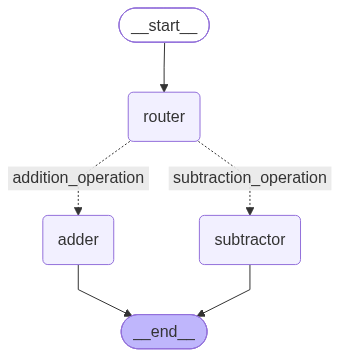

In [40]:
from typing import TypedDict,List 
from langgraph.graph import StateGraph,START,END

class AgentState(TypedDict):
    num1 : int 
    num2 : int 
    operation : str 
    finalnum : int 

def addition_node(state:AgentState) -> AgentState:
    """ This node performs addition"""
    state['finalnum'] = state['num1']+state['num2']
    return state

def subtraction_node(state:AgentState) -> AgentState: 
    """ This node performs subtraction"""             
    state['finalnum'] = state['num1']-state['num2']    
    return state                              

def decide_next_node(state:AgentState)-> AgentState:
    """ This decides which node to call (addition or subtraction)"""
    if state['operation'] == "+":
        return "addition_operation"
    elif state['operation'] == "-":
        return "subtraction_operation"

# create the graph structure 
graph = StateGraph(AgentState)
graph.add_node("adder",addition_node)
graph.add_node("subtractor",subtraction_node)
graph.add_node("router",lambda state:state) #passthrough function 
graph.add_edge(START,"router")  

graph.add_conditional_edges(
                "router",decide_next_node, 
                {
                    # return keywords used in function : Node    
                    "addition_operation":"adder",
                    "subtraction_operation":"subtractor"
                }
            )
graph.add_edge("adder",END)
graph.add_edge("subtractor",END)

app = graph.compile()
app

In [43]:
# result = app.invoke(AgentState(num1=10,num2=5,operation="+"))
result = app.invoke({"num1":5,"num2":7,"operation":"+"})
result

{'num1': 5, 'num2': 7, 'operation': '+', 'finalnum': 12}

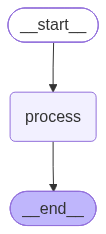

In [4]:
# Agent bot demo 
from typing import TypedDict,List 
from langchain_core.messages import HumanMessage
from langchain_openrouter import ChatOpenRouter
from langgraph.graph import StateGraph,START,END
from dotenv import load_dotenv
import os
import sys 

load_dotenv()

class AgentState(TypedDict):
    messages : List[HumanMessage]

llm = ChatOpenRouter(model="deepseek/deepseek-v4.1-flash",
                        api_key=os.getenv("OPENROUTER_API_KEY"))
# llm.invoke("what are agents?")

def process(state:AgentState)-> AgentState:
    response = llm.invoke(state['messages'])
    print(f"\n You : {state['messages'][0].content}")
    print(f"\nAI : {response.content}")
    # return state 

graph = StateGraph(AgentState)
graph.add_node("process",process)
graph.add_edge(START,"process")
graph.add_edge("process",END)

agent = graph.compile()
agent 

In [6]:
while True:
    user_input = input("Enter: ")
    if user_input == "exit":
        break
    response = agent.invoke({"messages":[HumanMessage(content=user_input)]})
    print(response)


 You : hi

AI : Hi! How can I help you today?
{'messages': [HumanMessage(content='hi', additional_kwargs={}, response_metadata={})]}

 You : who are you?

AI : I’m an AI assistant powered by a large language model, accessed via an API. I don’t have a personal identity or human experiences, but I’m here to help answer questions, explain ideas, write, brainstorm, code, and more. How can I help you?
{'messages': [HumanMessage(content='who are you?', additional_kwargs={}, response_metadata={})]}
